# Past tense across all wav2vec2 layers

**Question:** in which layer of wav2vec2-base is the English past tense represented best, and how does it compare to the -s inflections the paper studied?

The feasibility notebook (`notebooks/feasibility/feasibility_demo.ipynb`, Part 4) answered this for **layer 8 only**. This notebook runs the same analysis on **all 12 layers** (0–11), using the results of the full run on Alliance. All the calculations reuse the feasibility scripts in `scripts/feasibility/`, so layer 8 here is directly comparable to the feasibility demo's layer-8 results.

**What you need**
- The analogy results of all layers in `outputs/analogy/`. They come from the full run on Alliance; to copy them to a laptop, see `README.md`, "Past tense across layers".
- Python with `pandas`, `numpy`, `matplotlib` and `seaborn`. No GPU or PyTorch.

**What it produces:** tables and figures in `outputs/feasibility/layers/`, which are small and committed to git.

Run the cells from top to bottom. The whole notebook takes about a minute.

## 1. Setup

This finds the repository root, so the notebook works from any folder. It then imports two things:
- `compare_layers`: the per-layer analysis functions (`scripts/layers/compare_layers.py`).
- `common`, as `C`: the feasibility scripts' shared constants and statistics (`scripts/feasibility/common.py`).

Two settings you can change:
- `LAYERS`: which layers to analyze.
- `N_BOOT`: the number of bootstrap resamples for the confidence intervals. 2000 is what the feasibility notebook uses; lower it to, e.g., 300 for a quick look.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# find the repo root (the folder that contains scripts/layers/)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/layers/compare_layers.py").exists())
sys.path.insert(0, str(REPO / "scripts/layers"))
import compare_layers as L      # per-layer analysis (this project)
C = L.C                         # feasibility common.py: paths, constants, rank_summary(), plotting helpers

LAYERS = list(range(12))        # layers to analyze
N_BOOT = 2000                   # bootstrap resamples per cell (feasibility notebook: 2000)

C.set_style()
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repo:", REPO)

repo: /Users/tanyadjavaherpour/Documents/McMaster/RA/Morph-2-Vec


## 2. Check that every layer's results are there

Each layer has **two** results files, one per model:
- **Word**: the word probe. A small linear map trained on top of that layer to tell spoken words apart; this is the paper's "Word" model.
- **Wav2Vec**: the raw hidden states of that layer, with no probe.

The table below should show `True` everywhere. A `False` means that file wasn't copied, or that layer's run didn't finish.

In [2]:
check = pd.DataFrame({layer: {model: path.exists() for model, path in L.results_paths(layer).items()}
                      for layer in LAYERS}).T.rename_axis("layer")
display(check.T)
assert check.all().all(), "some results files are missing (see the False cells above)"

layer,0,1,2,3,4,5,6,7,8,9,10,11
Word,True,True,True,True,True,True,True,True,True,True,True,True
Wav2Vec,True,True,True,True,True,True,True,True,True,True,True,True


## 3. The past-tense verb pairs

Each past-tense pair (e.g. *walk → walked*) has an **automatic class** from the feasibility theory materials (`outputs/feasibility/theory/vbd_pairs_for_annotation.csv`). The pairs are the same for every layer, because they come from the data, not from the model.

- `regular_t`, `regular_d`, `regular_id`: regular pasts ending in [t], [d] or [ɪd] (*walked*, *played*, *wanted*).
- `semi_regular_candidate`, `devoicing`, `irregular_unclassified`: irregular pasts of different kinds (*kept*, *built*, *sang*).
- `suppletive`: a different root (*go → went*).
- `check`: needs a human look, e.g. *deal → dealt* is spelled like a regular past but changes its vowel.

Later, "**past, regular**" means pairs whose automatic class is regular [t]/[d]/[ɪd]. "**past, irregular**" means irregular pairs without modals (*could*, *would*), *be* and homographs (*wound*, *lay*). These are the same filters as in the feasibility notebook's Figure 7.

In [3]:
pairs = L.load_pairs()
print(f"{len(pairs)} past-tense pairs")
display(pairs.auto_class.value_counts().rename("pairs").to_frame())
display(pairs[["base", "inflected", "base_ipa", "past_ipa", "auto_class", "past_homophones"]].sample(8, random_state=0))

949 past-tense pairs


,pairs
auto_class,
regular_d,415
regular_id,223
regular_t,160
irregular_unclassified,72
check,50
semi_regular_candidate,21
devoicing,5
suppletive,3


,base,inflected,base_ipa,past_ipa,auto_class,past_homophones
871,burn,burnt,bɝn,bɝnt,check,NaN
568,associate,associated,ʌsoʊsiʌt,ʌsoʊsieɪtʌd,regular_id,NaN
249,push,pushed,pʊʃ,pʊʃt,regular_t,NaN
331,fear,feared,fɪɹ,fɪɹd,regular_d,NaN
492,breathe,breathed,bɹið,bɹiðd,regular_d,NaN
692,refer,referred,ɹɪfɝ,ɹɪfɝd,regular_d,NaN
820,assent,assented,ʌsɛnt,ʌsɛntɪd,regular_id,NaN
724,design,designed,dɪzaɪn,dɪzaɪnd,regular_d,NaN


## 4. What one analogy trial looks like (layer 8)

The pipeline tests analogies of the form **a : b :: c : ?**, e.g. *walk : walked :: play : ?*.
1. It takes the vector of *walked*, subtracts *walk*, and adds *play*.
2. It then ranks all 334,008 spoken word tokens by how close they are to the result.
3. `gt_label_rank` is the position of the correct answer (*played*) in that ranking. **0 means the correct word was the nearest one.**

From this rank come the two measures used throughout:
- **top-1 accuracy**: the share of trials with rank 0. Higher is better; 1 is perfect.
- **mean rank**: the average rank. Lower is better. It's sensitive to a few very bad trials, so it's shown on a log scale.

Below are a few past-tense trials of layer 8, read with the feasibility export code. The `allomorph_*_canon` columns give the ending of the source and target verb: `T`, `D`, or `IH D` (= [ɪd]).

In [4]:
C.RESULTS = L.results_paths(8)
results8 = {m: L.E.export_results(m) for m in C.MODELS}
vbd8 = L.E.export_vbd_trials(results8)
cols = ["model", "experiment", "base_from", "inflected_from", "base_to", "inflected_to",
        "allomorph_from_canon", "allomorph_to_canon", "class_from", "predicted_label", "gt_label_rank"]
display(vbd8[vbd8.experiment == "regular"][cols].sample(8, random_state=1))
print(f"layer 8: {len(vbd8):,} past-tense trials (both models)")

,model,experiment,base_from,inflected_from,base_to,inflected_to,allomorph_from_canon,allomorph_to_canon,class_from,predicted_label,gt_label_rank
1200,Word,regular,lose,lost,bring,brought,AO S T,AO T,irregular,back,21
2078,Word,regular,dash,dashed,grasp,grasped,T,T,regular,grasped,0
1610,Word,regular,come,came,ride,rode,EY M,OW D,irregular,rate,1774
4159,Wav2Vec,regular,lend,lent,may,might,T,AY T,irregular,made,7
2169,Word,regular,tangle,tangled,suppose,supposed,D,D,regular,supposed,0
4448,Wav2Vec,regular,sleep,slept,run,ran,EH P T,AE N,irregular,rung,9
4938,Wav2Vec,regular,do,did,ride,rode,IH D,OW D,irregular,write,1107
1813,Word,regular,make,made,be,were,D,W ER,irregular,bade,3574


layer 8: 6,000 past-tense trials (both models)


## 5. Run the analysis on every layer

For each layer, this does exactly what Part 4 of the feasibility notebook does for layer 8:

- **[t] / [d] / [ɪd] grid** (feasibility Figure 6). Regular → regular trials, split by the ending of the source verb (*a : b*) and of the target verb (*c : ?*). E.g. "[t] → [ɪd]" asks whether *walk : walked* helps find *wanted* from *want*.
- **Conditions** (feasibility Figure 7). Past regular, past irregular, plural -s, 3sg -s and the random-pair control. All are *within-class* analogies: regular → regular, irregular → irregular, plural → plural, and so on.
- **Per verb.** The mean rank of every regular target verb, to find the verbs that fail.

**Confidence intervals** (95%) come from resampling *verbs*, not trials, as in the feasibility notebook, because trials that share a verb aren't independent. It prints each layer number as it goes.

In [5]:
grids, conds, verbs = [], [], []
for layer in LAYERS:
    print(layer, end=" ", flush=True)
    g, c, v = L.layer_tables(layer, pairs, N_BOOT)
    grids.append(g); conds.append(c); verbs.append(v)
grid, cond, per_verb = (pd.concat(x, ignore_index=True) for x in (grids, conds, verbs))
print("\ndone:", len(grid), "grid cells,", len(cond), "condition cells,", len(per_verb), "verb rows")

0 

1 

2 

3 

4 

...

8 

9 

10 

11 


done: 216 grid cells, 168 condition cells, 12984 verb rows


## 6. Sanity check: layer 8 vs. the feasibility demo's layer-8 results

The feasibility demo ran layer 8 on a desktop GPU; this run did all 12 layers on Alliance. Because of the different GPU and package versions, numbers should be **close but not identical**:
- Top-1 accuracies should usually agree within a few points.
- Trial counts should be about the same.
- Mean ranks can differ more, because a handful of very bad trials dominates them.

A large, systematic difference would mean something in the run went wrong, so check this before reading the layer comparison.

In [6]:
cmp8 = L.layer8_vs_feasibility(grid, cond)
if cmp8 is None:
    print("layer 8 not analyzed, or the feasibility demo's tables not found")
else:
    cmp8["top1_diff"] = cmp8.top1_ours - cmp8.top1_feasibility
    display(cmp8.round(3))
    print(f"median |top-1 difference|: {cmp8.top1_diff.abs().median():.3f}")

,figure,model,cell,top1_ours,top1_feasibility,mean_rank_ours,mean_rank_feasibility,n_trials_ours,n_trials_feasibility,top1_diff
0,Figure 6,Wav2Vec,[d] → [d],0.764,0.753,3.665,4.634,233,235,0.011
1,Figure 6,Wav2Vec,[d] → [t],0.747,0.792,12.095,34.177,95,96,-0.044
2,Figure 6,Wav2Vec,[d] → [ɪd],0.610,0.610,8.985,7.934,136,136,0.000
3,Figure 6,Wav2Vec,[t] → [d],0.720,0.673,2.010,1.663,100,101,0.047
4,Figure 6,Wav2Vec,[t] → [t],0.923,0.923,0.115,0.192,26,26,-0.000
5,Figure 6,Wav2Vec,[t] → [ɪd],0.566,0.547,6.830,4.038,53,53,0.019
6,Figure 6,Wav2Vec,[ɪd] → [d],0.677,0.662,2.391,2.083,133,133,0.015
7,Figure 6,Wav2Vec,[ɪd] → [t],0.557,0.607,3.623,2.689,61,61,-0.049
8,Figure 6,Wav2Vec,[ɪd] → [ɪd],0.776,0.821,1.448,1.776,67,67,-0.045
9,Figure 6,Word,[d] → [d],0.833,0.847,3.970,3.834,233,235,-0.014


median |top-1 difference|: 0.013


## 7. Main result: past tense vs. -s across layers

How to read the figure:
- **Columns:** the word probe (left) and raw wav2vec2 hidden states (right).
- **Rows:** top-1 accuracy (top; higher is better) and mean rank (bottom; log scale, lower is better).
- **x-axis:** the layer, 0–11.
- **Lines:** each analogy condition. The grey dashed line is the random-pair control, i.e. what an analogy with a meaningless difference vector achieves.
- **Shaded bands:** 95% confidence intervals. Where two bands overlap, the difference isn't reliable.

Things to look for:
- Which layer the **past, regular** line peaks at, and whether that's the same layer as the -s lines.
- Whether **past, irregular** improves at any layer, or stays far below regular.
- Whether the probe beats raw wav2vec2 at every layer, or only at some.

  wrote figures/fig_layers_conditions.png/.pdf


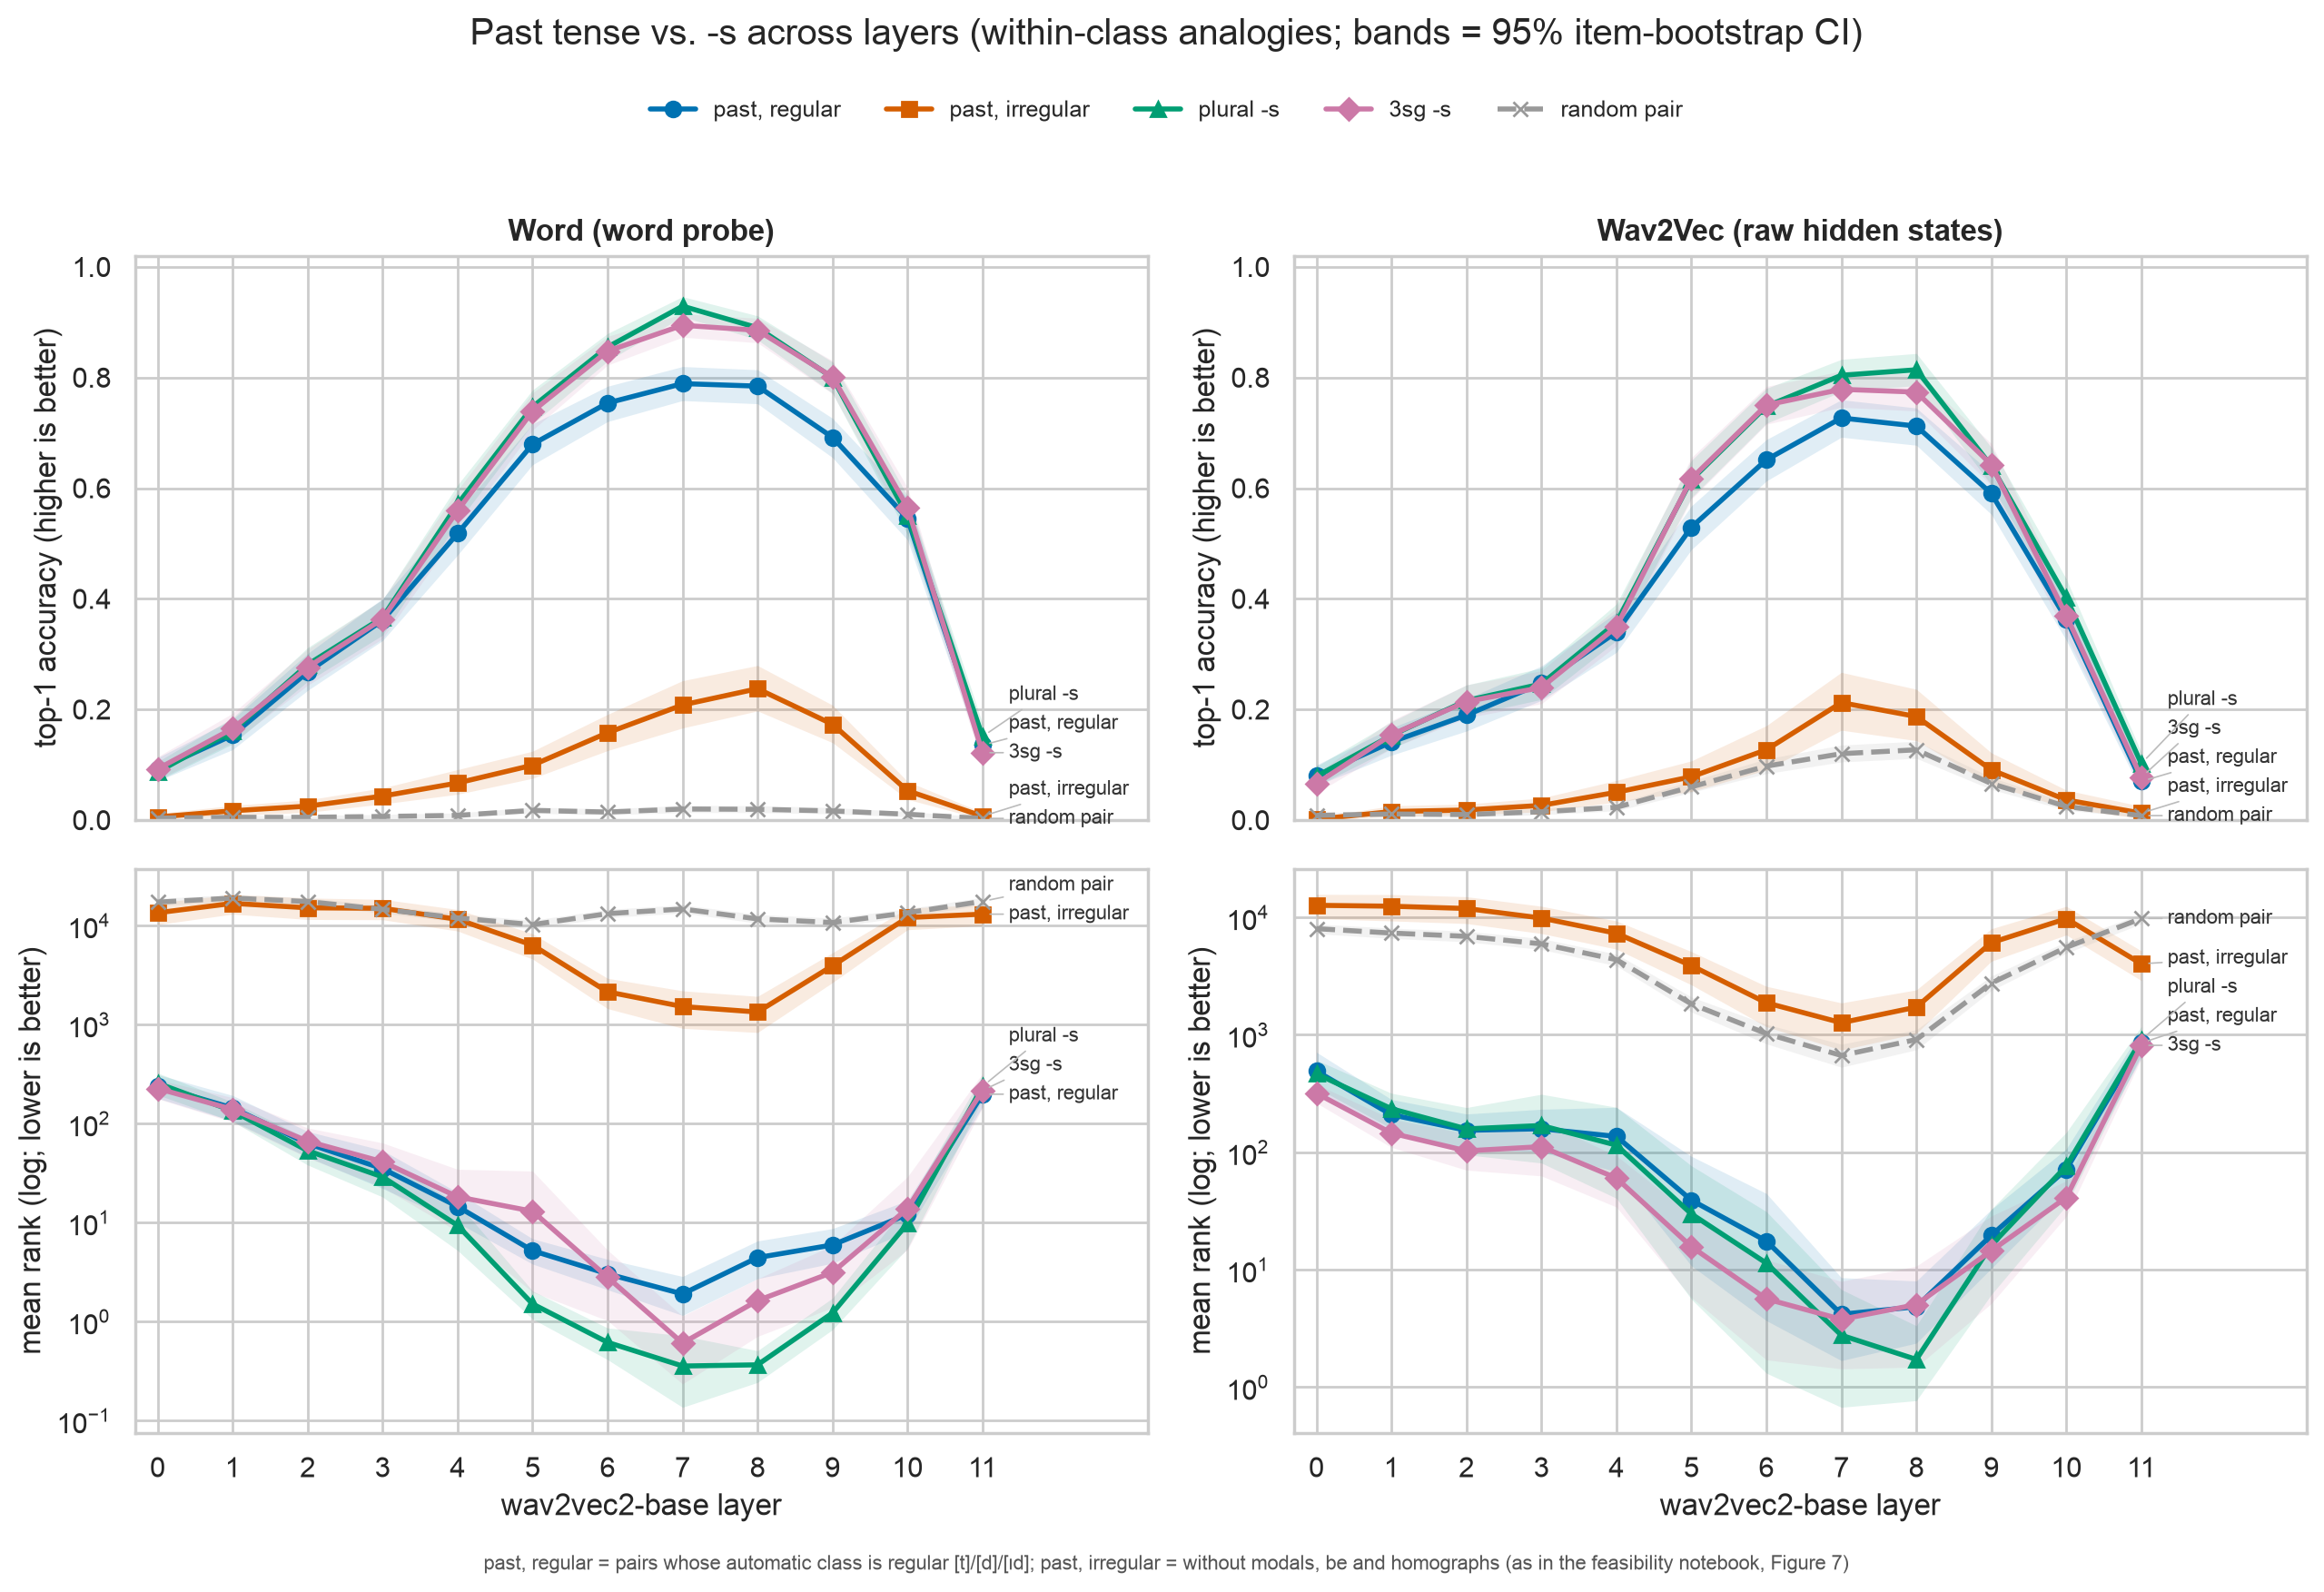

In [7]:
L.fig_conditions(cond, LAYERS)
display(Image(filename=str(L.FIGURES / "fig_layers_conditions.png")))

## 8. The best layer for each condition

For each model and condition, this gives the layer with the highest top-1 accuracy and the layer with the lowest mean rank, with their confidence intervals.

The two criteria can disagree: top-1 rewards getting most trials exactly right, while mean rank punishes rare bad failures. Look at the confidence intervals too. If the best layer's interval overlaps with its neighbours', several layers are about equally good, and the peak should be described as a *range* of layers rather than a single one.

In [8]:
best = L.best_layers(cond)
display(best.round(3))

,model,condition,best_layer_top1,top1,top1_lo,top1_hi,best_layer_mean_rank,mean_rank,mean_lo,mean_hi
0,Wav2Vec,3sg VBZ regular,7,0.779,0.746,0.812,7,3.780,1.432,7.959
1,Wav2Vec,past irregular,7,0.184,0.138,0.229,7,1257.428,774.675,1796.071
2,Wav2Vec,"past irregular (no modals, be, homographs)",7,0.212,0.162,0.267,7,1267.411,741.667,1870.379
3,Wav2Vec,past regular,7,0.714,0.681,0.747,7,32.640,3.033,85.888
4,Wav2Vec,past regular (auto-class regular only),7,0.727,0.692,0.760,7,4.170,1.683,8.553
5,Wav2Vec,plural NNS regular,8,0.814,0.785,0.843,8,1.721,0.767,3.329
6,Wav2Vec,random pair (→ NNS / VBZ),8,0.127,0.112,0.142,7,666.806,530.042,832.036
7,Word,3sg VBZ regular,7,0.894,0.873,0.915,7,0.605,0.234,1.136
8,Word,past irregular,8,0.214,0.176,0.252,8,1601.092,930.537,2538.708
9,Word,"past irregular (no modals, be, homographs)",8,0.237,0.197,0.279,8,1337.525,830.834,1925.886


To check whether neighbouring layers are really different, here is top-1 accuracy (with its 95% CI) for every layer, for the two past-tense conditions:

In [9]:
focus = cond[cond.condition.isin([L.COND_PAST_REG_CLEAN, L.COND_PAST_IRR_CLEAN])].copy()
focus["top1 [95% CI]"] = focus.apply(lambda r: f"{r.top1:.2f} [{r.top1_lo:.2f}, {r.top1_hi:.2f}]", axis=1)
display(focus.pivot_table(index="layer", columns=["model", "condition"], values="top1 [95% CI]", aggfunc="first"))

model                                        Wav2Vec                                                                              Word  \
condition past irregular (no modals, be, homographs) past regular (auto-class regular only) past irregular (no modals, be, homographs)   
layer                                                                                                                                    
0                                  0.00 [0.00, 0.00]                      0.08 [0.06, 0.10]                          0.01 [0.00, 0.01]   
1                                  0.02 [0.01, 0.03]                      0.14 [0.12, 0.17]                          0.02 [0.01, 0.03]   
2                                  0.02 [0.01, 0.03]                      0.19 [0.16, 0.22]                          0.03 [0.01, 0.04]   
3                                  0.03 [0.02, 0.04]                      0.25 [0.22, 0.28]                          0.04 [0.03, 0.06]   
4                                  0.05 [0.03, 0.07]                      0.34 [0.30, 0.38]                          0.07 [0.05, 0.09]   
5                                  0.08 [0.05, 0.11]                      0.53 [0.49, 0.57]                          0.10 [0.08, 0.12]   
6                                  0.13 [0.09, 0.17]                      0.65 [0.61, 0.69]                          0.16 [0.13, 0.19]   
7                                  0.21 [0.16, 0.27]                      0.73 [0.69, 0.76]                          0.21 [0.17, 0.25]   
8                                  0.19 [0.14, 0.24]                      0.71 [0.68, 0.74]                          0.24 [0.20, 0.28]   
9                                  0.09 [0.06, 0.12]                      0.59 [0.55, 0.63]                          0.17 [0.14, 0.21]   
10                                 0.04 [0.02, 0.05]                      0.36 [0.32, 0.40]                          0.05 [0.04, 0.07]   
11                                 0.01 [0.00, 0.02]                      0.07 [0.05, 0.09]                          0.01 [0.00, 0.01]   

model                                             
condition past regular (auto-class regular only)  
layer                                             
0                              0.09 [0.07, 0.11]  
1                              0.15 [0.13, 0.18]  
2                              0.27 [0.23, 0.30]  
3                              0.36 [0.32, 0.40]  
4                              0.52 [0.48, 0.56]  
5                              0.68 [0.64, 0.72]  
6                              0.75 [0.72, 0.78]  
7                              0.79 [0.76, 0.82]  
8                              0.78 [0.75, 0.81]  
9                              0.69 [0.66, 0.73]  
10                             0.55 [0.51, 0.58]  
11                             0.14 [0.11, 0.16]

## 9. [t] / [d] / [ɪd]: does the ending matter, and where?

The paper found that the -s inflection transfers across its pronunciations [s] / [z] / [ɪz] almost as well as within them. This checks the same for the past tense, at every layer.

- **Panels:** one per target ending (columns) and model (rows).
- **Lines:** the source ending.
- If the three lines in a panel are close together, the model treats [t], [d] and [ɪd] as the same "past tense" at that layer.
- If one line is clearly lower, e.g. transfer *into* [ɪd], which was the weak spot at layer 8, the ending still matters there.

  wrote figures/fig_layers_allomorph_top1.png/.pdf


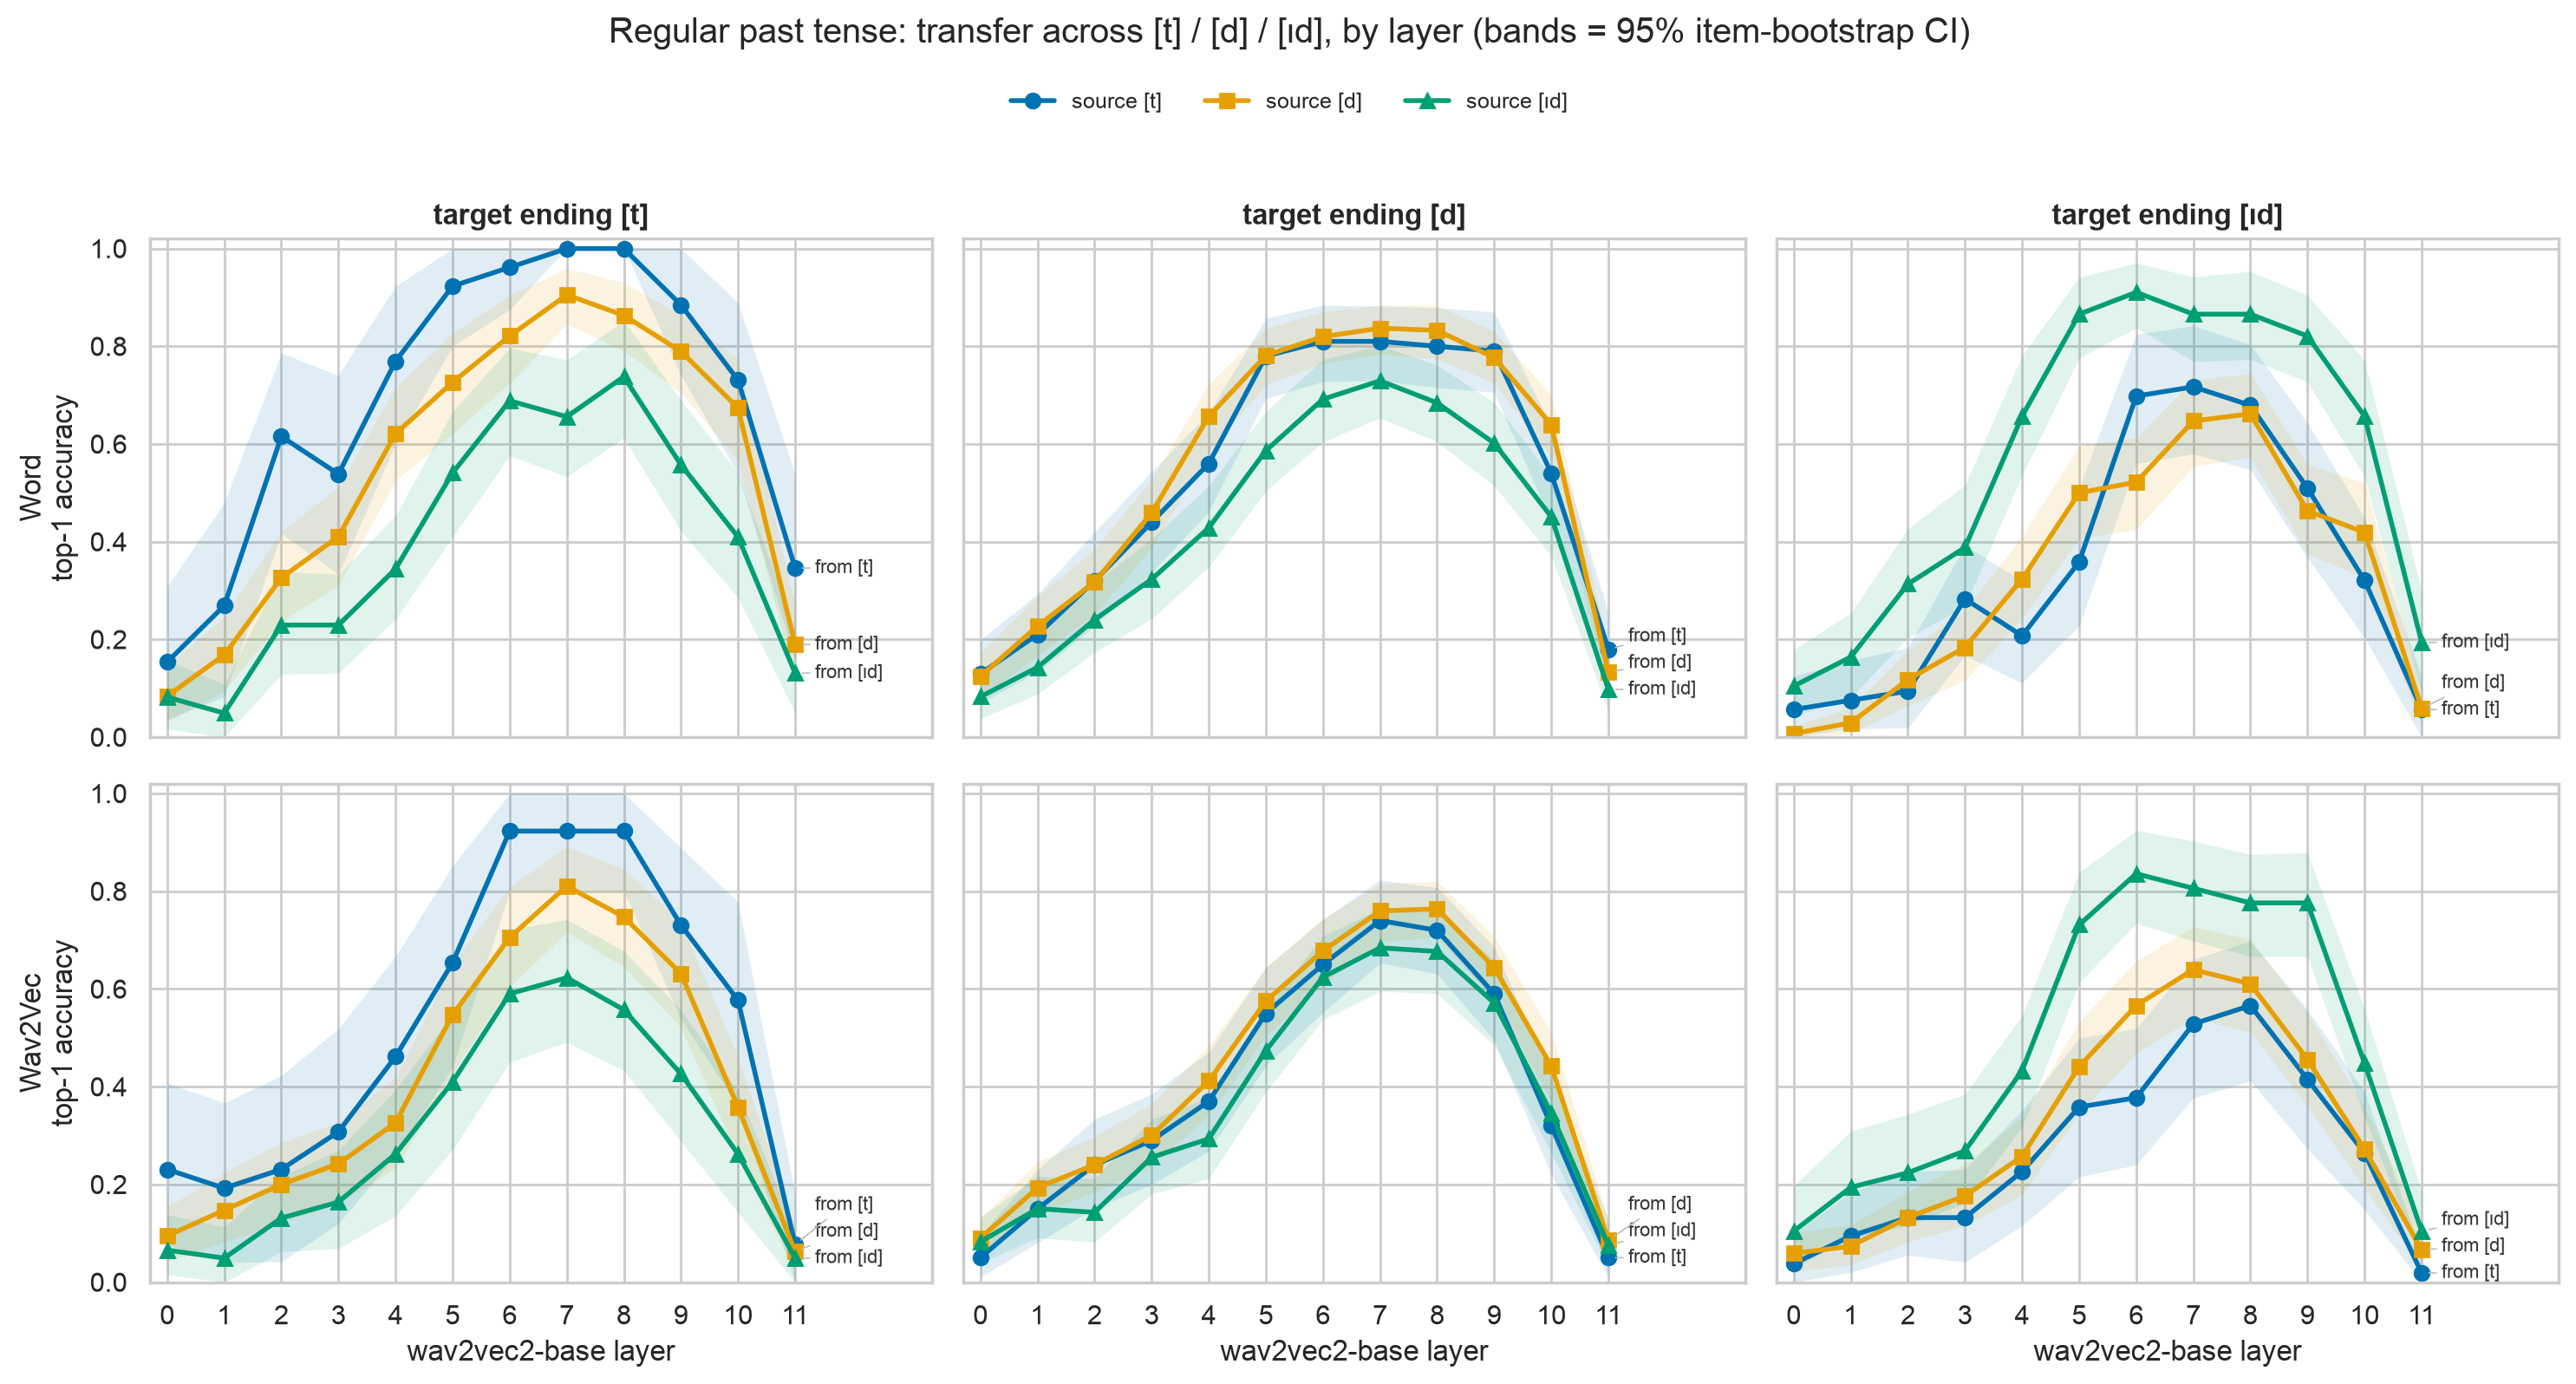

In [10]:
L.fig_allomorph_top1(grid, LAYERS)
display(Image(filename=str(L.FIGURES / "fig_layers_allomorph_top1.png")))

The same data as feasibility Figure 6, drawn once per layer: rows are the source ending, columns the target ending, and each cell's number is its top-1 accuracy. Darker means better. A uniform 3×3 block means the ending doesn't matter at that layer.

  wrote figures/fig_layers_allomorph_grids_word.png/.pdf


  wrote figures/fig_layers_allomorph_grids_wav2vec.png/.pdf


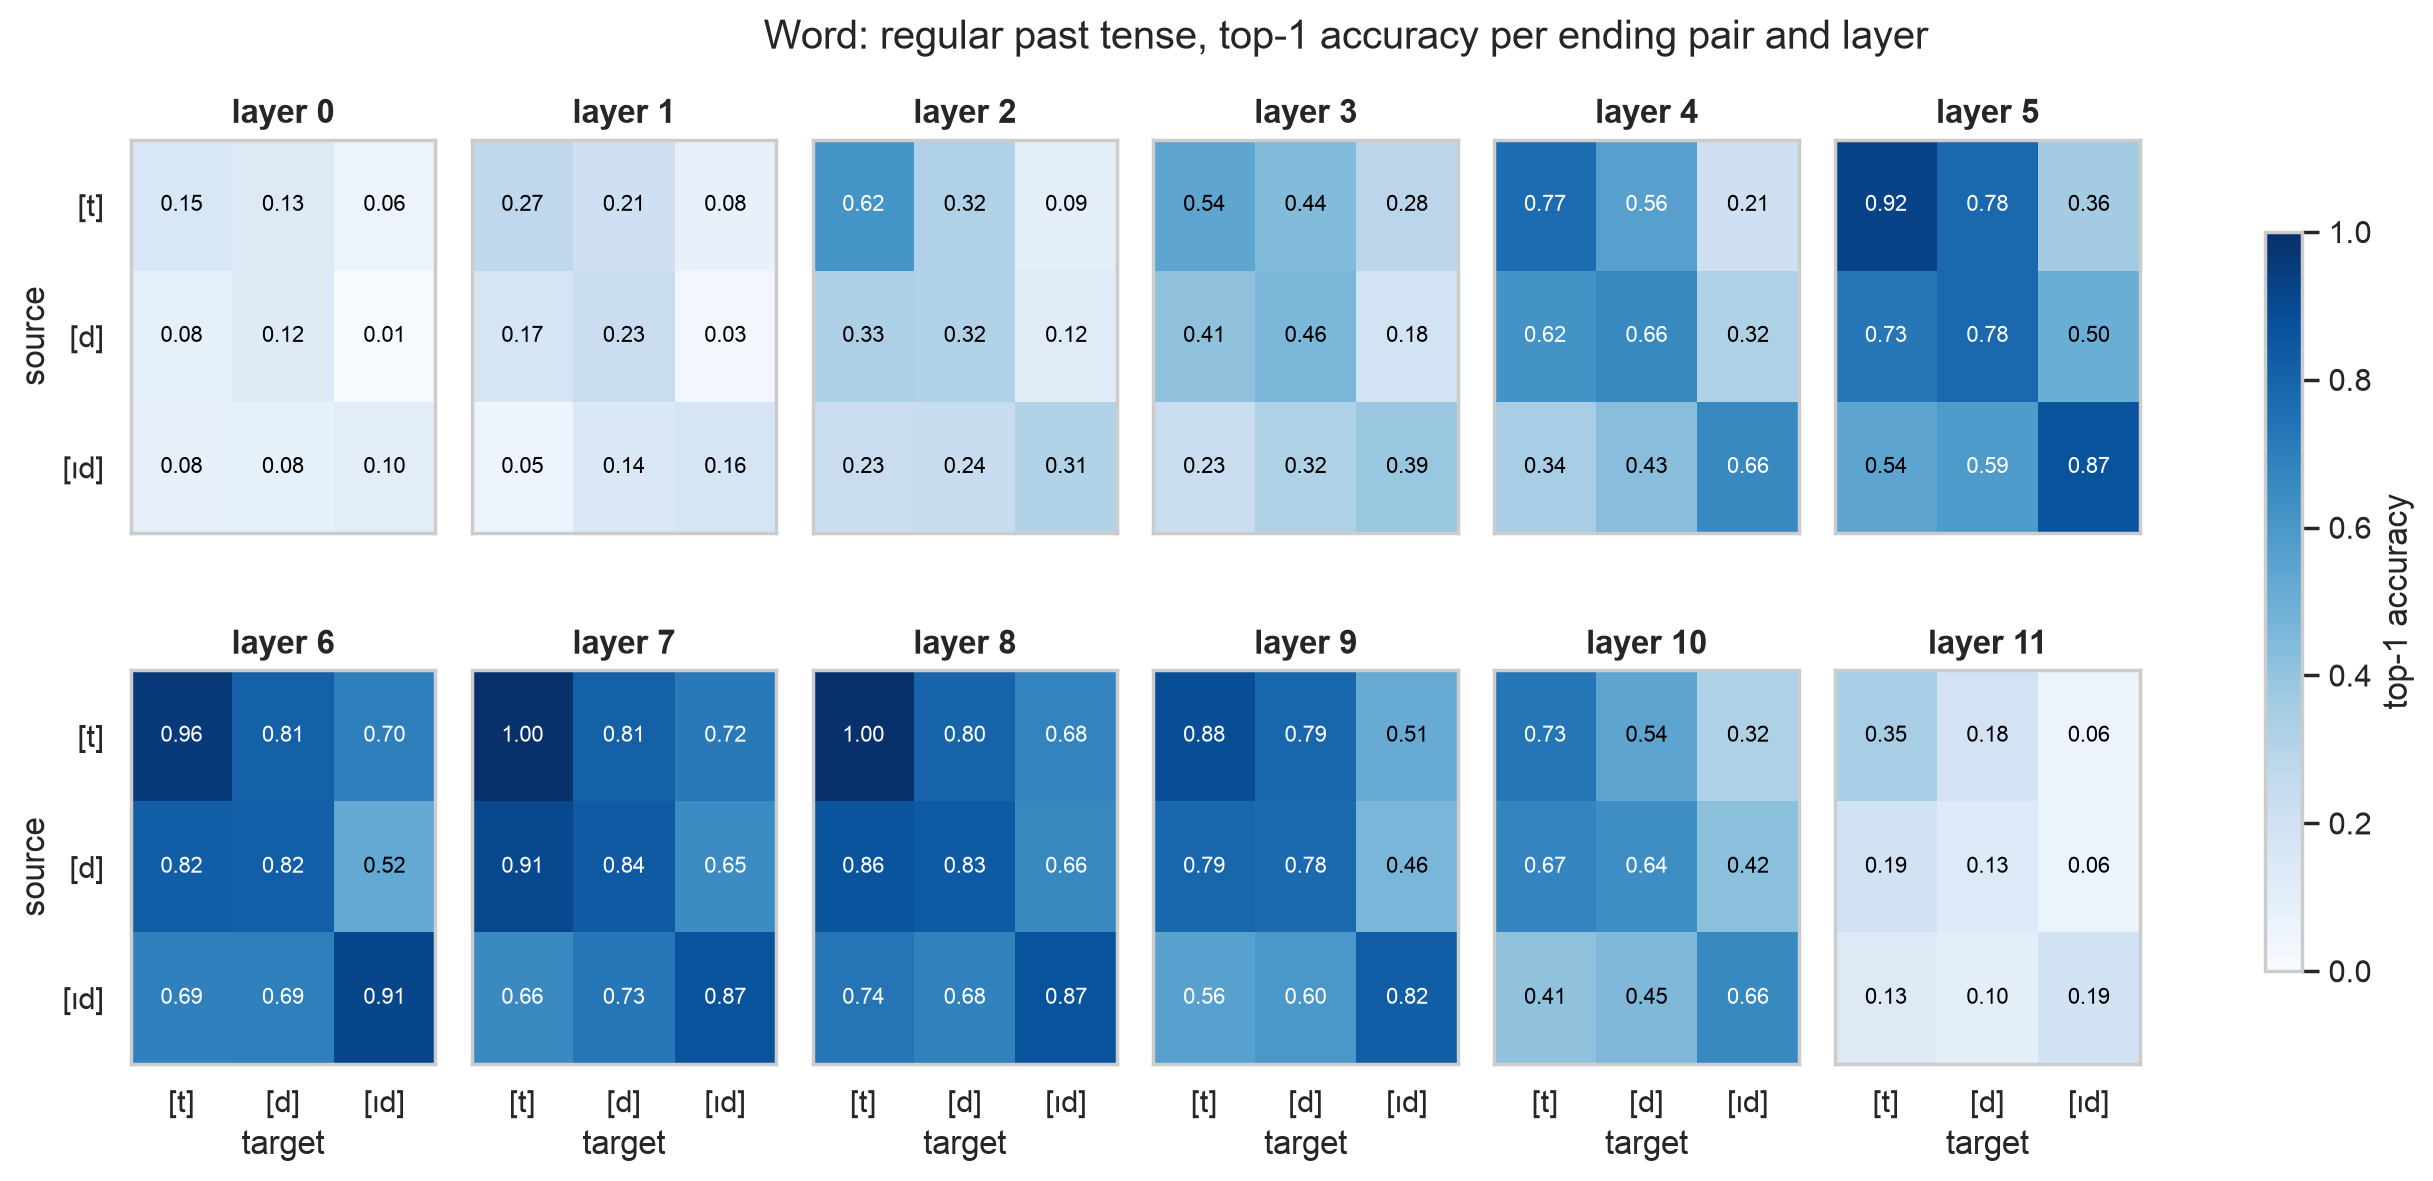

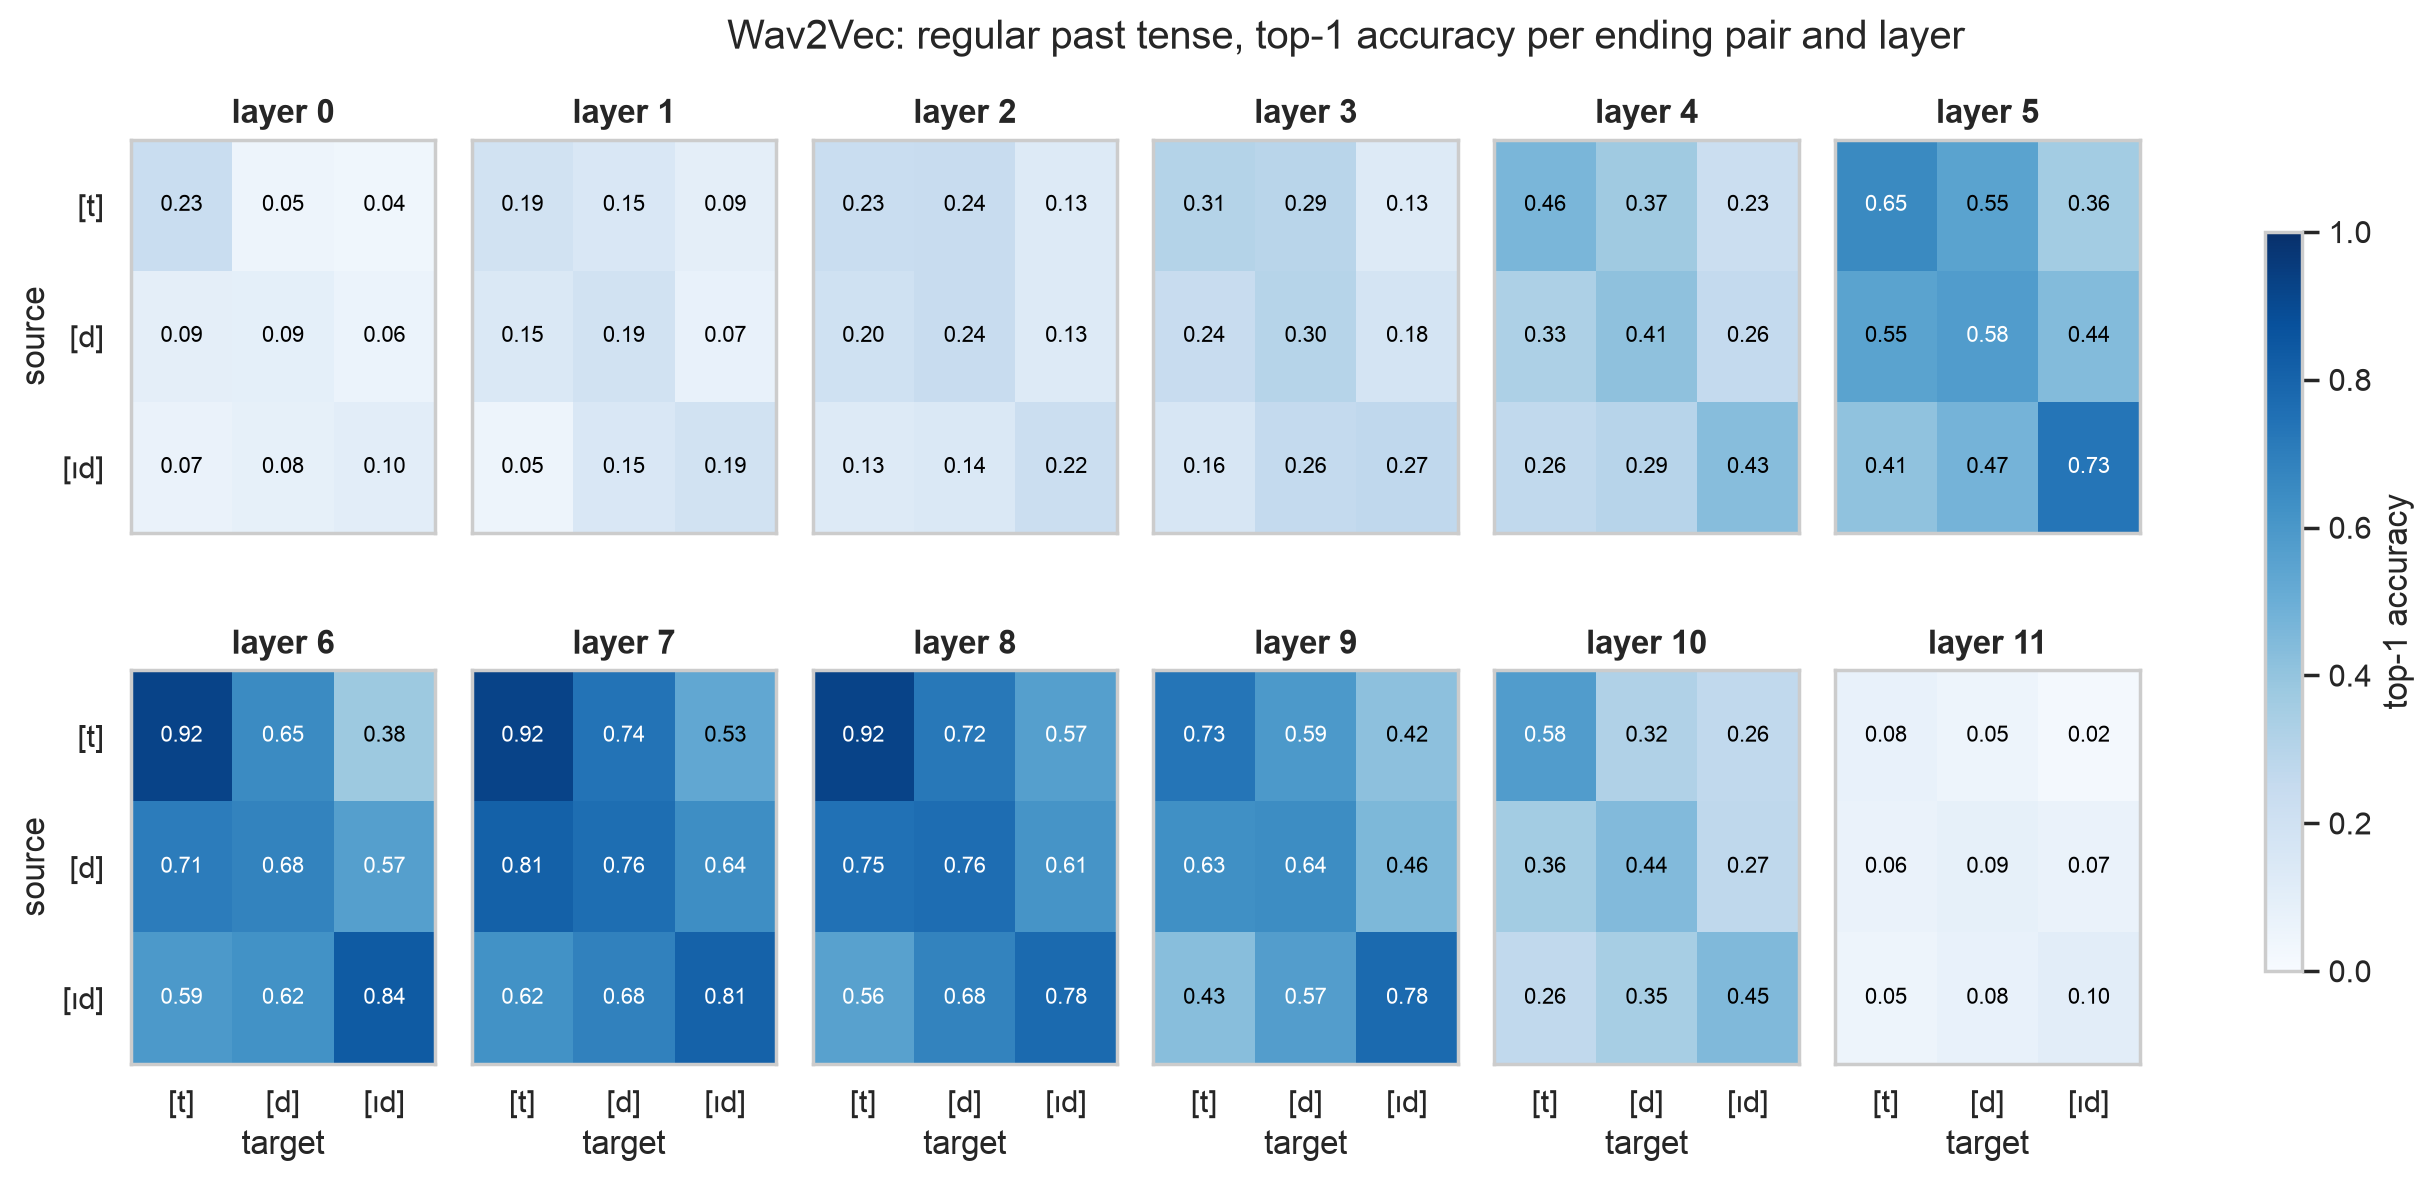

In [11]:
L.fig_allomorph_grids(grid, LAYERS)
for model in C.MODELS:
    display(Image(filename=str(L.FIGURES / f"fig_layers_allomorph_grids_{model.lower()}.png")))

## 10. Which verbs fail, and at which layers

At layer 8, the feasibility notebook found that the regular-past mean rank was driven by a few verbs. Some change their stem (*deal → dealt*); others have a past form that sounds like another word (*rowed* ~ *road*).

The first table lists the 15 regular target verbs with the worst mean rank in the **word probe at its best layer**. The second follows those same verbs across all layers. A verb that is bad everywhere points to a problem with the item, e.g. a homophone. A verb that is bad only in some layers says something about those layers.

In [12]:
best_layer = int(best.set_index(["model", "condition"]).loc[("Word", L.COND_PAST_REG_CLEAN), "best_layer_top1"])
pv = per_verb[per_verb.model == "Word"]
worst = (pv[pv.layer == best_layer].groupby(["base_to", "inflected_to", "past_sounds_like"], as_index=False)
         .agg(mean_rank=("mean_rank", "mean"), trials=("trials", "sum"))
         .sort_values("mean_rank", ascending=False).head(15))
display(Markdown(f"**Word probe, layer {best_layer}: the 15 worst regular target verbs**"))
display(worst.round(1))

across = (pv[pv.inflected_to.isin(worst.inflected_to)]
          .groupby(["inflected_to", "layer"]).mean_rank.mean().unstack("layer").reindex(worst.inflected_to))
display(Markdown("**The same verbs across layers (mean rank; lower is better)**"))
display(across.round(0))

**Word probe, layer 7: the 15 worst regular target verbs**

,base_to,inflected_to,past_sounds_like,mean_rank,trials
122,curl,curled,curl'd,316.0,2
436,side,sided,,130.0,2
304,miss,missed,mist,100.0,2
311,nose,nosed,,93.0,1
290,lower,lowered,,64.5,2
59,border,bordered,,45.0,1
280,learn,learnt,,44.0,2
458,stalk,stalked,,38.0,1
411,round,rounded,,35.0,1
438,sight,sighted,cited,24.0,1


**The same verbs across layers (mean rank; lower is better)**

layer,0,1,2,3,4,5,6,7,8,9,10,11
inflected_to,,,,,,,,,,,,
curled,71.0,14.0,13.0,3.0,7.0,62.0,4.0,316.0,110.0,568.0,213.0,334.0
sided,2481.0,511.0,310.0,318.0,295.0,131.0,163.0,130.0,126.0,248.0,186.0,539.0
missed,294.0,224.0,242.0,19.0,21.0,16.0,56.0,100.0,62.0,35.0,12.0,143.0
nosed,7468.0,509.0,227.0,40.0,74.0,43.0,150.0,93.0,462.0,320.0,11.0,636.0
lowered,958.0,698.0,208.0,102.0,46.0,6.0,6.0,64.0,78.0,80.0,32.0,1820.0
bordered,210.0,121.0,82.0,238.0,54.0,1.0,17.0,45.0,0.0,11.0,109.0,24.0
learnt,2664.0,1206.0,841.0,242.0,136.0,61.0,30.0,44.0,73.0,64.0,236.0,564.0
stalked,736.0,240.0,73.0,6.0,2.0,7.0,130.0,38.0,156.0,77.0,5.0,1776.0
rounded,82.0,145.0,138.0,71.0,4.0,0.0,7.0,35.0,71.0,97.0,18.0,89.0


## 11. Save the tables

This writes the tables next to the figures, in `outputs/feasibility/layers/tables/`:
- `layers_conditions.csv`: section 7.
- `layers_best.csv`: section 8.
- `layers_allomorph_grid.csv`: section 9.
- `layers_per_verb.csv.gz`: section 10.
- `layer8_vs_feasibility.csv`: section 6.

Everything in `outputs/feasibility/layers/` is small (under 1 MB), so commit it. The group can then see the results on GitHub without access to Fir:

```bash
git add outputs/feasibility/layers notebooks/layers
git commit -m "Past tense across all 12 wav2vec2 layers: results"
git push
```

In [13]:
L.TABLES.mkdir(parents=True, exist_ok=True)
grid.to_csv(L.TABLES / "layers_allomorph_grid.csv", index=False)
cond.to_csv(L.TABLES / "layers_conditions.csv", index=False)
per_verb.to_csv(L.TABLES / "layers_per_verb.csv.gz", index=False)
best.to_csv(L.TABLES / "layers_best.csv", index=False)
if cmp8 is not None:
    cmp8.to_csv(L.TABLES / "layer8_vs_feasibility.csv", index=False)
for f in sorted(L.OUT.rglob("*.*")):
    print(f"{f.relative_to(C.ROOT)}  ({f.stat().st_size / 1024:.0f} KB)")

outputs/feasibility/layers/figures/fig_layers_allomorph_grids_wav2vec.pdf  (33 KB)
outputs/feasibility/layers/figures/fig_layers_allomorph_grids_wav2vec.png  (219 KB)
outputs/feasibility/layers/figures/fig_layers_allomorph_grids_word.pdf  (33 KB)
outputs/feasibility/layers/figures/fig_layers_allomorph_grids_word.png  (218 KB)
outputs/feasibility/layers/figures/fig_layers_allomorph_top1.pdf  (39 KB)
outputs/feasibility/layers/figures/fig_layers_allomorph_top1.png  (610 KB)
outputs/feasibility/layers/figures/fig_layers_conditions.pdf  (44 KB)
outputs/feasibility/layers/figures/fig_layers_conditions.png  (551 KB)
outputs/feasibility/layers/past_tense_layers.pdf  (1829 KB)
outputs/feasibility/layers/tables/layer8_vs_feasibility.csv  (4 KB)
outputs/feasibility/layers/tables/layers_allomorph_grid.csv  (28 KB)
outputs/feasibility/layers/tables/layers_best.csv  (2 KB)
outputs/feasibility/layers/tables/layers_conditions.csv  (25 KB)
outputs/feasibility/layers/tables/layers_per_verb.csv.gz  (66 